# Optimal domain decomposition strategy

Using the built-in cartisian map to decompose the $N^3$ qube in an arbetrary dimension $n$ we investigate

- How many dimension should be decompose the domain in?
- Along which axis should we slice it?

**For $n=1$ we can decompose along 3 axis**

<div>
<img src="images/d1_a0.png" width="400"/>
<img src="images/d1_a1.png" width="400"/>
<img src="images/d1_a2.png" width="400"/>
</div>

**For $n=2$ we can decompose along a combination of axis with 3 different combinations**

<div>
<img src="images/d2_a01.png" width="400"/>
<img src="images/d2_a02.png" width="400"/>
<img src="images/d2_a12.png" width="400"/>
</div>

**For $n=3$ we there is only one option**

<div>
<img src="images/d3_a012.png" width="400"/>
</div>

Images are with $N=10$ and $6$ ranks for $n=1,2$ and $8$ ranks for for $n=3$

# Results using SendRecv Function

We run all the configurations for $N=500-1000$

In [7]:
import pandas as pd
import os
import matplotlib.pyplot as plt

# Concat all dfs into one
csv_list = os.listdir("results/my_results")
csv_list.sort()
df_list = []
for i in range(0, len(csv_list)):
    csv_path = "results/my_results/" + csv_list[i]
    df_list.append(pd.read_csv(csv_path))
df = pd.concat(df_list)

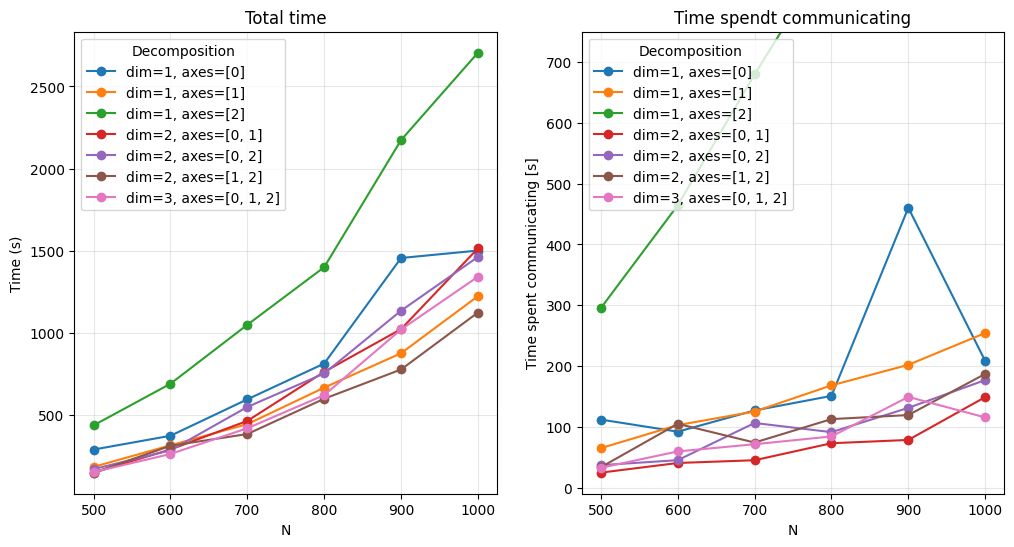

In [8]:
# Plot total calculation time
groups = df[["decomb_dim", "decomb_axes", "N", "time", "comm_time"]].groupby(["decomb_dim", "decomb_axes", "N"]).mean()
plot_df = groups.reset_index()

fig, ax = plt.subplots(1,2, figsize=(12, 6))
for (decomb_dim, decomb_axes), data in plot_df.groupby(["decomb_dim", "decomb_axes"]):
    data = data.sort_values("N")
    ax[0].plot(
        data["N"],
        data["time"],
        marker="o",
        label=f"dim={decomb_dim}, axes={decomb_axes}",
    )

    ax[1].plot(
        data["N"],
        #data["comm_time"]/data["time"],
        data["comm_time"],
        marker="o",
        label=f"dim={decomb_dim}, axes={decomb_axes}",
    )

ax[0].set_xlabel("N")
ax[0].set_ylabel("Time (s)")
ax[0].legend(title="Decomposition")
ax[0].grid(True, alpha=0.3)
ax[0].set_title("Total time")

ax[1].set_xlabel("N")
ax[1].set_ylabel("Time spent communicating [s]")
ax[1].set_ylim(-10,750)
ax[1].legend(title="Decomposition", loc="upper left")
ax[1].set_title("Time spendt communicating")
ax[1].grid(True, alpha=0.3)
plt.show()

# Result Using Send/recv in the way that is described

In [9]:
# Concat all dfs into one
csv_list = os.listdir("results/my_results_newsendrecv")
csv_list.sort()
df_list = []
for i in range(0, len(csv_list)):
    csv_path = "results/my_results_newsendrecv/" + csv_list[i]
    df_list.append(pd.read_csv(csv_path))
df2 = pd.concat(df_list)

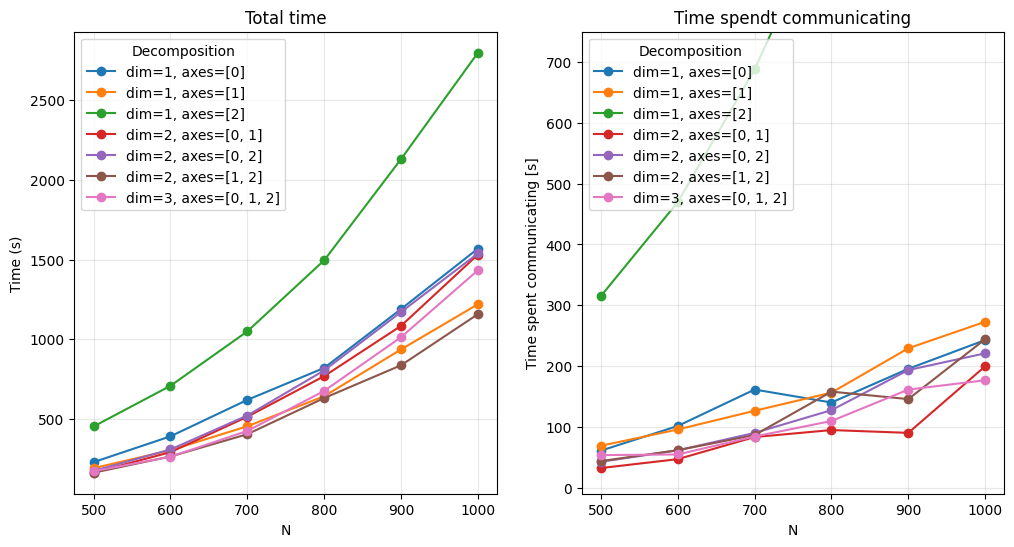

In [10]:
# Plot total calculation time
groups2 = df2[["decomb_dim", "decomb_axes", "N", "time", "comm_time"]].groupby(["decomb_dim", "decomb_axes", "N"]).mean()
plot_df2 = groups2.reset_index()

fig, ax = plt.subplots(1,2, figsize=(12, 6))
for (decomb_dim, decomb_axes), data in plot_df2.groupby(["decomb_dim", "decomb_axes"]):
    data = data.sort_values("N")
    ax[0].plot(
        data["N"],
        data["time"],
        marker="o",
        label=f"dim={decomb_dim}, axes={decomb_axes}",
    )

    ax[1].plot(
        data["N"],
        #data["comm_time"]/data["time"],
        data["comm_time"],
        marker="o",
        label=f"dim={decomb_dim}, axes={decomb_axes}",
    )

ax[0].set_xlabel("N")
ax[0].set_ylabel("Time (s)")
ax[0].legend(title="Decomposition")
ax[0].grid(True, alpha=0.3)
ax[0].set_title("Total time")

ax[1].set_xlabel("N")
ax[1].set_ylabel("Time spent communicating [s]")
ax[1].set_ylim(-10,750)
ax[1].legend(title="Decomposition", loc="upper left")
ax[1].set_title("Time spendt communicating")
ax[1].grid(True, alpha=0.3)
plt.show()

# Difference plot

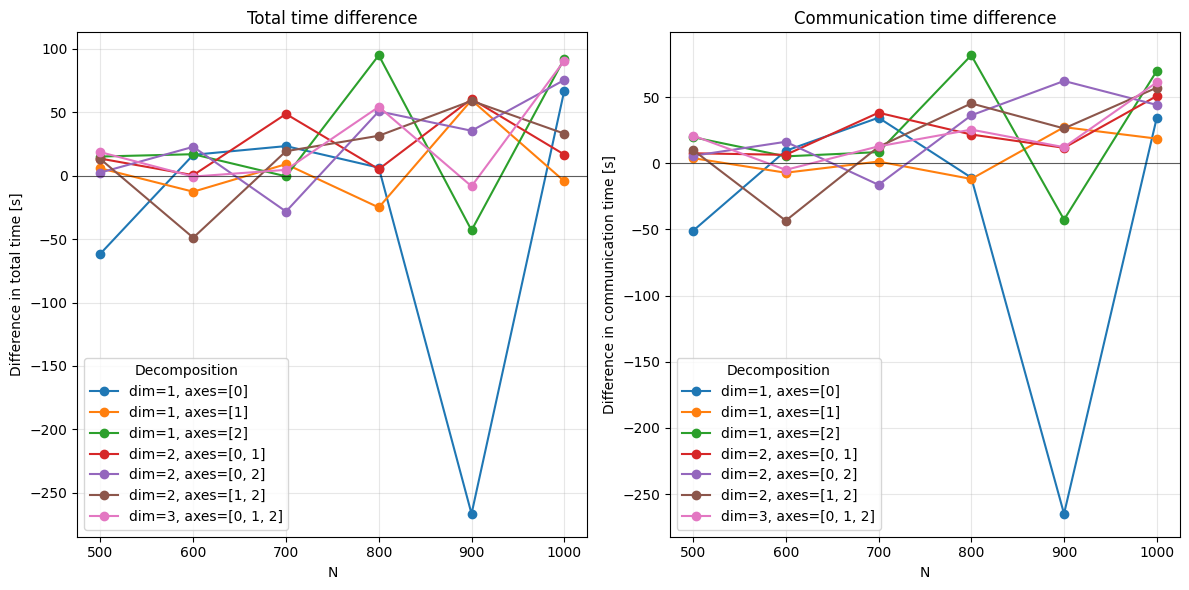

In [13]:
# Compare matching configurations: positive values mean df2 took more time than df.
comparison = plot_df.merge(
    plot_df2,
    on=["decomb_dim", "decomb_axes", "N"],
    suffixes=("_df", "_df2"),
    validate="one_to_one",
)

comparison["time_diff"] = comparison["time_df2"] - comparison["time_df"]
comparison["comm_time_diff"] = comparison["comm_time_df2"] - comparison["comm_time_df"]

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
for (decomb_dim, decomb_axes), data in comparison.groupby(["decomb_dim", "decomb_axes"]):
    data = data.sort_values("N")
    label = f"dim={decomb_dim}, axes={decomb_axes}"
    ax[0].plot(data["N"], data["time_diff"], marker="o", label=label)
    ax[1].plot(data["N"], data["comm_time_diff"], marker="o", label=label)

ax[0].axhline(0, color="black", linewidth=0.8, alpha=0.6)
ax[0].set_xlabel("N")
ax[0].set_ylabel("Difference in total time [s]")
ax[0].set_title("Total time difference")
ax[0].legend(title="Decomposition")
ax[0].grid(True, alpha=0.3)

ax[1].axhline(0, color="black", linewidth=0.8, alpha=0.6)
ax[1].set_xlabel("N")
ax[1].set_ylabel("Difference in communication time [s]")
ax[1].set_title("Communication time difference")
ax[1].legend(title="Decomposition", loc="lower left")
ax[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()